Input sentence:
Deep learning models learn patterns

Model Output:
[ 0.17457305  0.04076806  0.41872025 -0.13665892  0.21383323]

Input Weight Wxh Shape: (4, 3)
Recurrent Weight Whh Shape: (3, 3)
Hidden Bias Shape: (3,)
Output Weight Why Shape: (3, 1)

Manual Hidden States:
[[ 0.2609664  -0.07962976 -0.2724786 ]
 [ 0.17991728 -0.2967319   0.24377696]
 [ 0.55984486 -0.03847923 -0.59097791]
 [-0.07943458 -0.22431849 -0.07541228]
 [ 0.32441211 -0.110234   -0.13713026]]

Manual Output:
[ 0.17457302  0.04076806  0.41872019 -0.1366589   0.21383327]

Keras Output:
[ 0.17457305  0.04076806  0.41872025 -0.13665892  0.21383323]

Verification:
Outputs match: True


/tmp/ipykernel_1693/3798265136.py:171: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


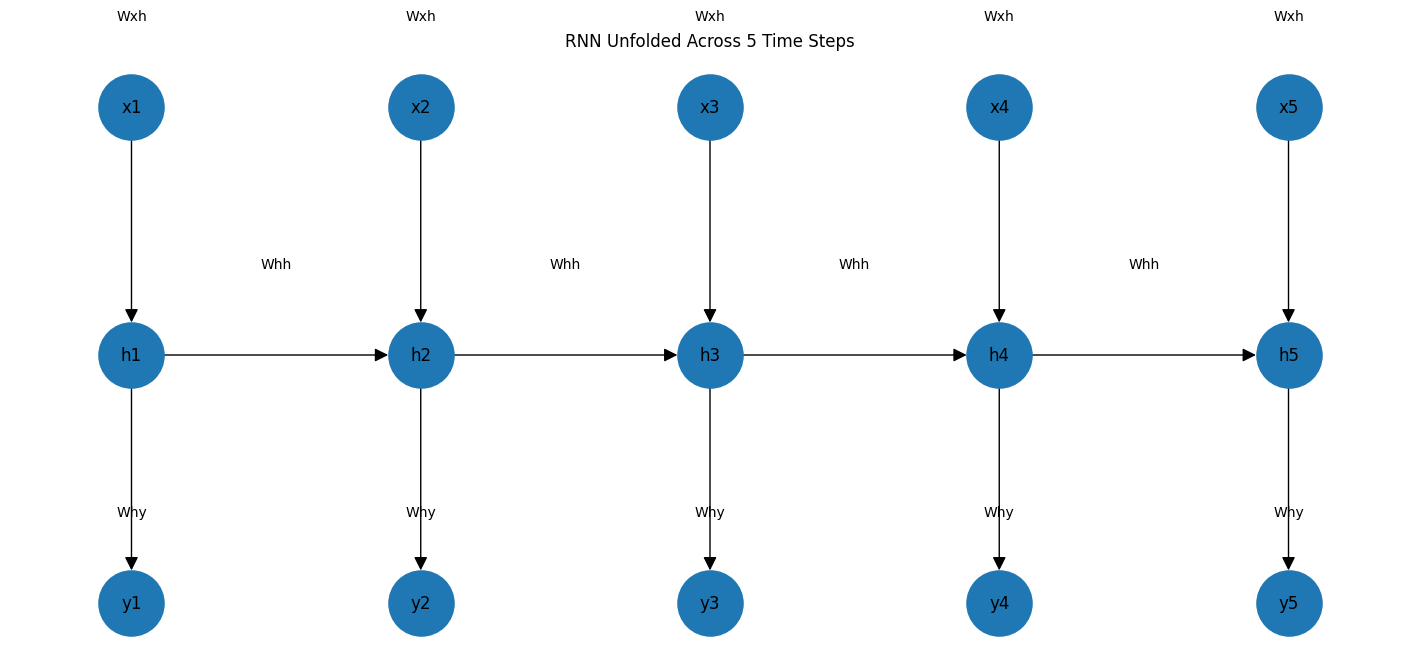

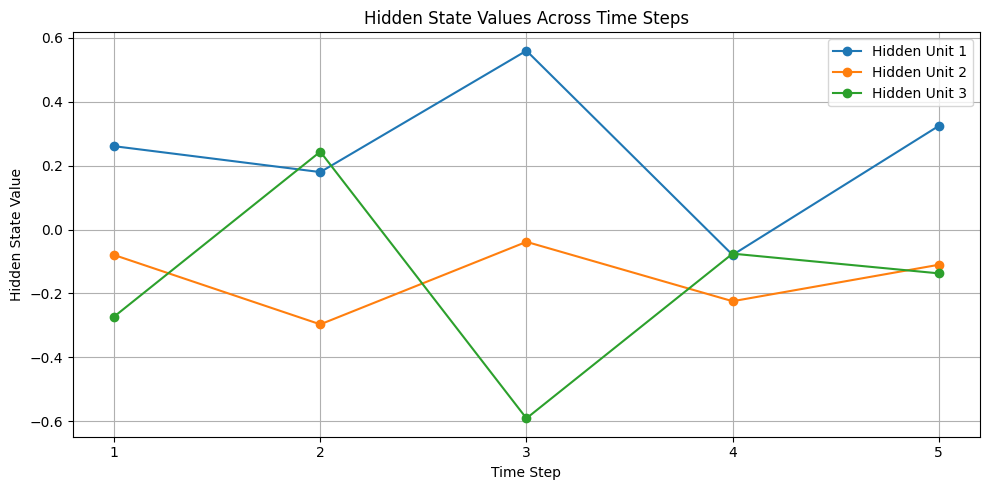


Hidden State Values at Each Time Step:

Time Step 1 (Deep):
[ 0.2609664  -0.07962976 -0.2724786 ]

Time Step 2 (learning):
[ 0.17991728 -0.2967319   0.24377696]

Time Step 3 (models):
[ 0.55984486 -0.03847923 -0.59097791]

Time Step 4 (learn):
[-0.07943458 -0.22431849 -0.07541228]

Time Step 5 (patterns):
[ 0.32441211 -0.110234   -0.13713026]

Experiment 14 completed successfully!


In [18]:
# EXPERIMENT 14: UNFOLDED RNN ARCHITECTURE VISUALIZATION

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import networkx as nx

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input

# -----------------------------------------
# 1. INITIALIZE
# -----------------------------------------

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

# Sample 5-word sentence
words = ["Deep", "learning", "models", "learn", "patterns"]

# Each word represented by a 4-dimensional numeric vector
X = np.array([
    [0.2, 0.1, 0.4, 0.3],
    [0.5, 0.2, 0.1, 0.4],
    [0.3, 0.6, 0.2, 0.1],
    [0.1, 0.4, 0.5, 0.2],
    [0.6, 0.3, 0.1, 0.5]
], dtype=np.float32)

X = X.reshape(1, 5, 4)

print("Input sentence:")
print(" ".join(words))

# -----------------------------------------
# 2. BUILD SIMPLE RNN
# -----------------------------------------

model = Sequential([
    Input(shape=(5, 4)),
    SimpleRNN(3, activation="tanh", return_sequences=True),
    Dense(1)
])

# -----------------------------------------
# 3. MODEL PREDICTION
# -----------------------------------------

output = model.predict(X, verbose=0)

print("\nModel Output:")
print(output.reshape(5))

# -----------------------------------------
# 4. EXTRACT RNN WEIGHTS
# -----------------------------------------

rnn_layer = model.layers[0]

Wxh, Whh, bh = rnn_layer.get_weights()

# Output layer weights
Why, by = model.layers[1].get_weights()

print("\nInput Weight Wxh Shape:", Wxh.shape)
print("Recurrent Weight Whh Shape:", Whh.shape)
print("Hidden Bias Shape:", bh.shape)
print("Output Weight Why Shape:", Why.shape)

# -----------------------------------------
# 5. MANUAL HIDDEN STATE CALCULATION
# -----------------------------------------

hidden_states = []

h = np.zeros(3)

for t in range(5):

    xt = X[0, t, :]

    h = np.tanh(
        np.dot(xt, Wxh) +
        np.dot(h, Whh) +
        bh
    )

    hidden_states.append(h.copy())

hidden_states = np.array(hidden_states)

# -----------------------------------------
# 6. VERIFY MANUAL OUTPUT WITH KERAS
# -----------------------------------------

manual_output = np.dot(hidden_states, Why) + by

print("\nManual Hidden States:")
print(hidden_states)

print("\nManual Output:")
print(manual_output.flatten())

print("\nKeras Output:")
print(output.flatten())

print("\nVerification:")
print("Outputs match:",
      np.allclose(manual_output, output[0], atol=1e-5))

# -----------------------------------------
# 7. DRAW UNFOLDED RNN USING NETWORKX
# -----------------------------------------

G = nx.DiGraph()

positions = {}

for t in range(5):

    # Input nodes
    x_node = f"x{t+1}"
    h_node = f"h{t+1}"
    y_node = f"y{t+1}"

    G.add_node(x_node)
    G.add_node(h_node)
    G.add_node(y_node)

    positions[x_node] = (t, 2)
    positions[h_node] = (t, 1)
    positions[y_node] = (t, 0)

    # Input to hidden connection
    G.add_edge(x_node, h_node)

    # Hidden to output connection
    G.add_edge(h_node, y_node)

    # Recurrent connection
    if t > 0:
        G.add_edge(f"h{t}", h_node)

# -----------------------------------------
# 8. VISUALIZE UNFOLDED RNN
# -----------------------------------------

plt.figure(figsize=(14, 6))

nx.draw(
    G,
    positions,
    with_labels=True,
    node_size=2200,
    font_size=12,
    arrows=True,
    arrowsize=20
)

# Weight labels
for t in range(5):

    plt.text(t, 2.35, "Wxh", ha="center")
    plt.text(t, 0.35, "Why", ha="center")

    if t > 0:
        plt.text(t - 0.5, 1.35, "Whh", ha="center")

plt.title("RNN Unfolded Across 5 Time Steps")
plt.axis("off")
plt.tight_layout()
plt.show()

# -----------------------------------------
# 9. PLOT HIDDEN STATE VALUES
# -----------------------------------------

plt.figure(figsize=(10, 5))

for i in range(3):

    plt.plot(
        range(1, 6),
        hidden_states[:, i],
        marker="o",
        label=f"Hidden Unit {i+1}"
    )

plt.title("Hidden State Values Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Hidden State Value")

plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# -----------------------------------------
# 10. DISPLAY OUTPUT VALUES
# -----------------------------------------

print("\nHidden State Values at Each Time Step:")

for t in range(5):

    print(f"\nTime Step {t+1} ({words[t]}):")
    print(hidden_states[t])

print("\nExperiment 14 completed successfully!")